In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import sys
import torch

# Add larndsim to path
sys.path.insert(0, 'src')

plt.rcParams['figure.dpi'] = 100

In [2]:
# Import JAX and larndsim for analytic distribution
import jax.numpy as jnp
from larndsim.consts_jax import build_params_class, load_detector_properties
from larndsim.fee_jax import get_adc_values_average_noise_vmap, get_average_hit_values

In [3]:
# Load simulation parameters
Params = build_params_class([])
params = load_detector_properties(
    Params,
    "src/larndsim/detector_properties/module0.yaml",
    "src/larndsim/pixel_layouts/multi_tile_layout-2.4.16_v4.yaml"
)
print(f"MAX_ADC_VALUES (max hits): {params.MAX_ADC_VALUES}")

MAX_ADC_VALUES (max hits): 10


In [4]:
# Load Monte Carlo variation data
filename = 'variation_results_2.h5'

with h5py.File(filename, 'r') as f:
    batch = f['batch_0']
    waveforms = batch['waveform'][:]  # (n_pixels, n_ticks)
    
    n_variations = f.attrs['n_variations']
    
    # Stack all variations: (n_variations, n_pixels, n_adc_samples)
    hit_adc = np.stack([batch[f'variation_{i}/hit_adc'][:] for i in range(n_variations)])
    hit_time = np.stack([batch[f'variation_{i}/hit_time'][:] for i in range(n_variations)])

print(f"Input shape:  waveform per pixel = {waveforms.shape[1]} ticks")
print(f"Output shape: {n_variations} variations x {hit_adc.shape[2]} ADC samples per pixel")
print(f"Total pixels: {waveforms.shape[0]}")

Input shape:  waveform per pixel = 2000 ticks
Output shape: 10000 variations x 10 ADC samples per pixel
Total pixels: 140


In [5]:
# Compute analytic distribution for all waveforms
print("Computing analytic distributions...")
wfs_jax = jnp.array(waveforms[:, 1:])  # Remove first tick as done in sim_jax.py
ticks_prob, charge_distrib = get_adc_values_average_noise_vmap(params, wfs_jax)

# Get expected values
expected_ticks, expected_adcs, hit_prob = get_average_hit_values(ticks_prob, charge_distrib)

print(f"ticks_prob shape: {ticks_prob.shape}  # (Npix, Nhits, Nticks-1)")
print(f"hit_prob shape: {hit_prob.shape}  # (Npix, Nhits) - probability each hit exists")

# Sanity check: hit_prob should equal sum of ticks_prob over ticks
check_sum = np.array(jnp.sum(ticks_prob, axis=2))
check_hit_prob = np.array(hit_prob)
print(f"\nSanity check: hit_prob == sum(ticks_prob, axis=2)?")
print(f"  Max difference: {np.max(np.abs(check_sum - check_hit_prob)):.2e}")

Computing analytic distributions...
ticks_prob shape: (140, 10, 1998)  # (Npix, Nhits, Nticks-1)
hit_prob shape: (140, 10)  # (Npix, Nhits) - probability each hit exists

Sanity check: hit_prob == sum(ticks_prob, axis=2)?
  Max difference: 0.00e+00


In [6]:
# Precompute waveform features
wf_max = np.max(np.abs(waveforms), axis=1)
wf_peak_time = np.argmax(waveforms, axis=1)
wf_integral = np.sum(waveforms, axis=1)
sorted_idx = np.argsort(wf_max)[::-1]  # Sort by signal strength

In [7]:
def fit_skewnorm(time_vals):
    """
    Fit a skew-normal distribution to time values.
    Returns: (a, loc, scale, success)
    """
    try:
        a, loc, scale = stats.skewnorm.fit(time_vals)
        return a, loc, scale, True
    except:
        return 0, np.mean(time_vals), np.std(time_vals), False

In [14]:
def plot_with_analytic_density(pix_idx, waveforms, hit_adc, hit_time, n_variations, 
                               ticks_prob, hit_prob):
    """Show waveform and hit time distributions with density=True.
    
    All distributions are normalized to integrate to 1:
    - MC histogram: density=True
    - Skew-normal fit: standard PDF
    - Analytic: ticks_prob / hit_prob (conditional on hit existing)
    """
    
    fig, axes = plt.subplots(1, 6, figsize=(16, 3))
    
    # Waveform in first position
    ax = axes[0]
    start = max(0, wf_peak_time[pix_idx]-100)
    end = min(waveforms.shape[1], wf_peak_time[pix_idx]+50)
    ax.plot(waveforms[pix_idx][start:end], lw=1.8)
    ax.set_title(f'Waveform (peak={wf_peak_time[pix_idx]})')
    ax.set_xlabel('tick')
    
    # Time samples with fits and analytic overlay
    for i in range(1, 6):
        ax = axes[i]
        
        # Monte Carlo data
        time_vals = hit_time[:, pix_idx, i]
        mask = time_vals < 1995
        time_vals = time_vals[mask]
        
        # Analytic distribution for this hit index
        analytic_prob = np.array(ticks_prob[pix_idx, i, :])  # (Nticks-1,)
        analytic_hit_prob = float(hit_prob[pix_idx, i])
        
        NBINS = 20
        if len(time_vals) > 1 and len(time_vals)/n_variations > 0.01:
            # Plot histogram with density=True (integrates to 1)
            counts, bins, _ = ax.hist(time_vals, bins=NBINS, alpha=0.7, color='C2', 
                                       density=True, label='MC')
            
            # Fit skew-normal (standard fit, PDF integrates to 1)
            a, loc, scale, success = fit_skewnorm(time_vals)
            
            if success:
                x = np.linspace(time_vals.min()-10, time_vals.max()+10, 100)
                pdf = stats.skewnorm.pdf(x, a, loc, scale)
                ax.plot(x, pdf, 'r-', lw=2, label='fit')
            
            # Analytic distribution - normalize to PDF (conditional on hit existing)
            # ticks_prob sums to hit_prob, so divide by hit_prob to get PDF
            tick_range = np.arange(len(analytic_prob))
            
            # Focus on the relevant time range
            t_min, t_max = int(time_vals.min()) - 5, int(time_vals.max()) + 5
            t_min = max(0, t_min)
            t_max = min(len(analytic_prob), t_max)
            
            # Normalize: divide by hit_prob to get conditional PDF
            # (probability density given that hit exists)
            if analytic_hit_prob > 1e-8:
                analytic_pdf = analytic_prob / analytic_hit_prob
            else:
                analytic_pdf = analytic_prob
            
            ax.plot(tick_range[t_min:t_max], analytic_pdf[t_min:t_max],
                    'b-', lw=2, alpha=0.8, label='analytic')
            
            ax.legend(fontsize=6)
            ax.set_title(f'Hit {i}: P_mc={len(time_vals)/n_variations:.2f}, P_an={analytic_hit_prob:.3f}', fontsize=9)
        else:
            ax.set_title(f'Hit {i}: insufficient data')
        
        ax.set_xlabel('Time [ticks]')
    
    plt.suptitle(f'Pixel {pix_idx}: density-normalized distributions', fontsize=12)
    plt.tight_layout()
    plt.show()

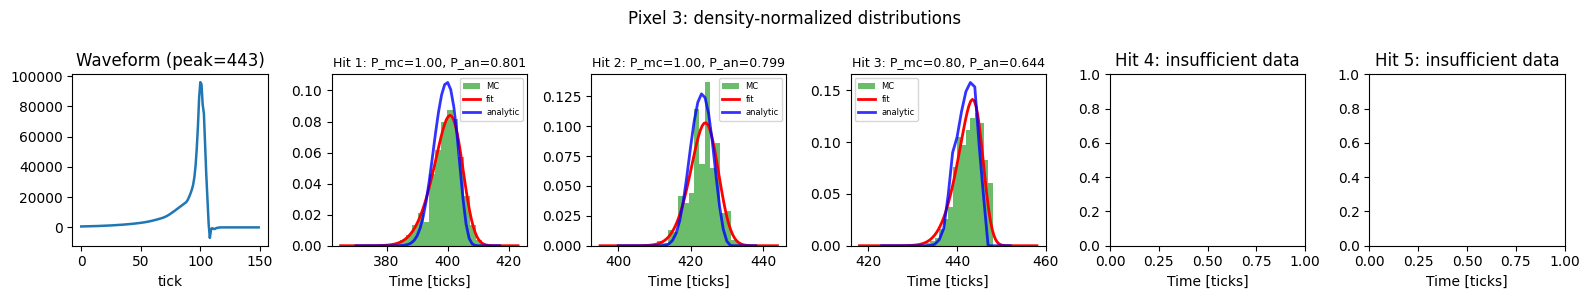

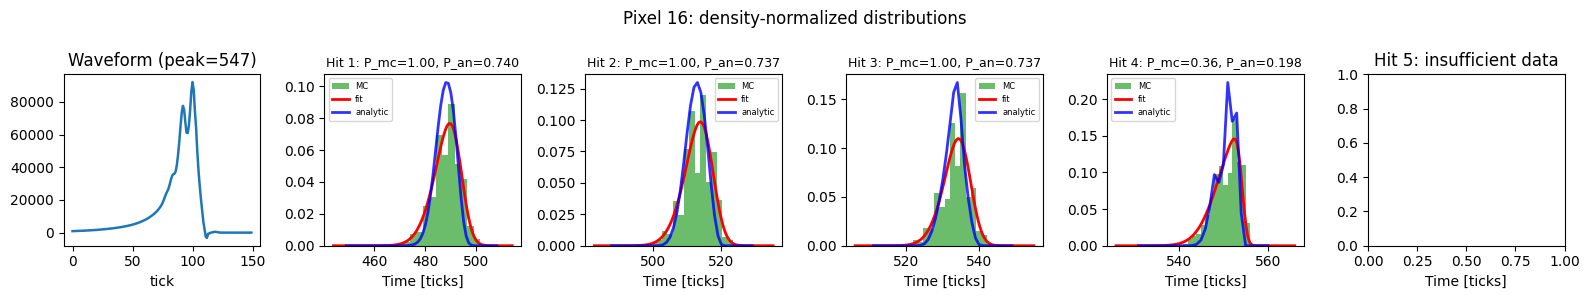

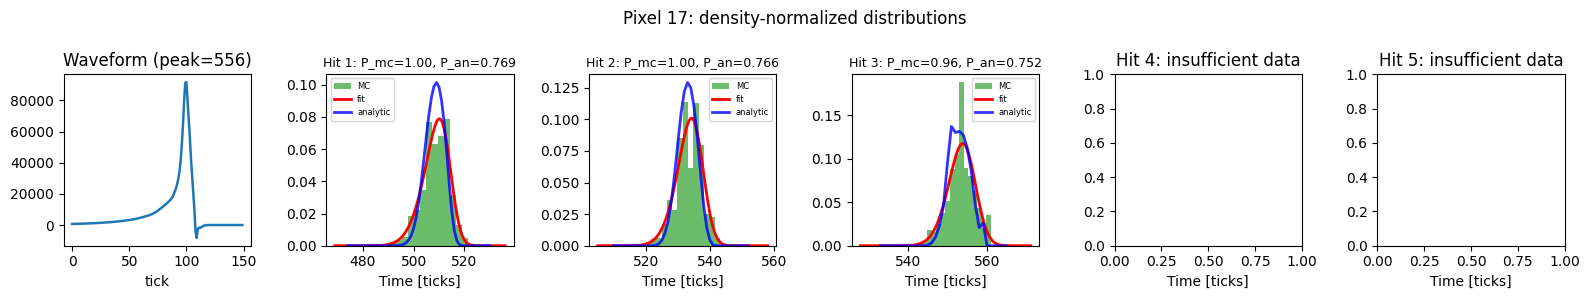

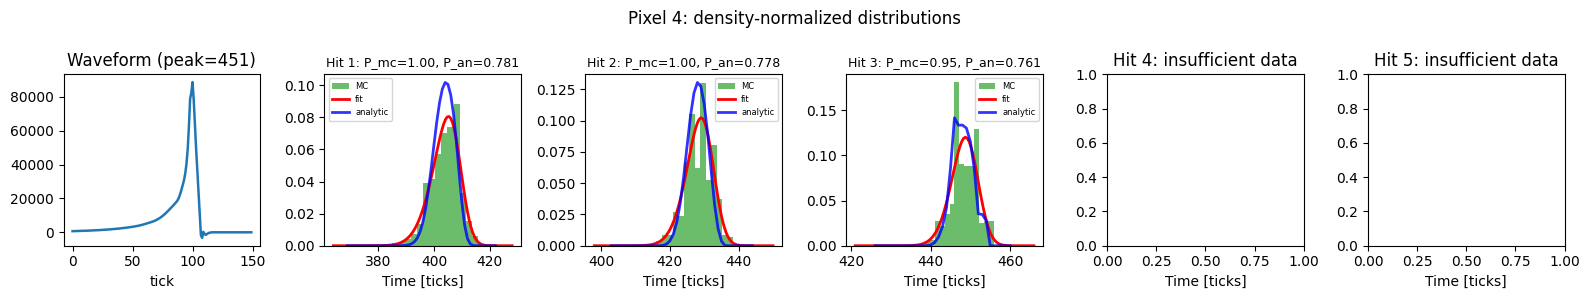

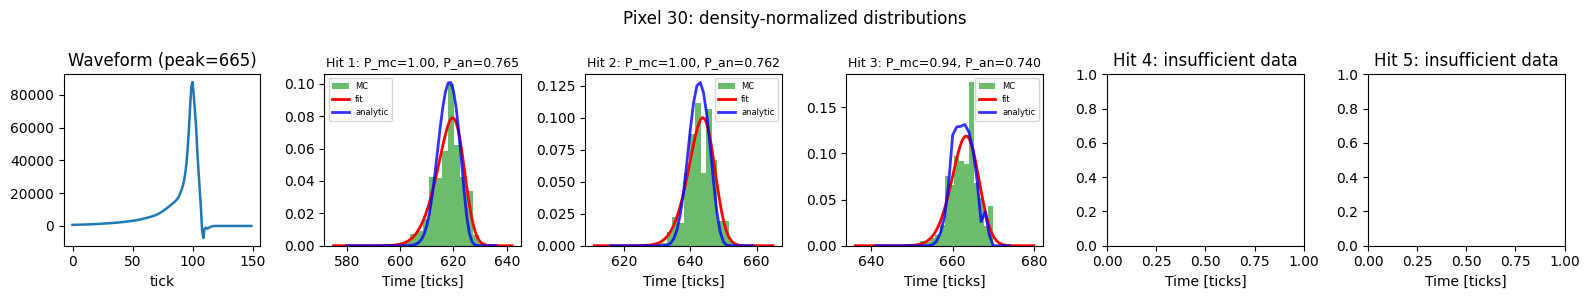

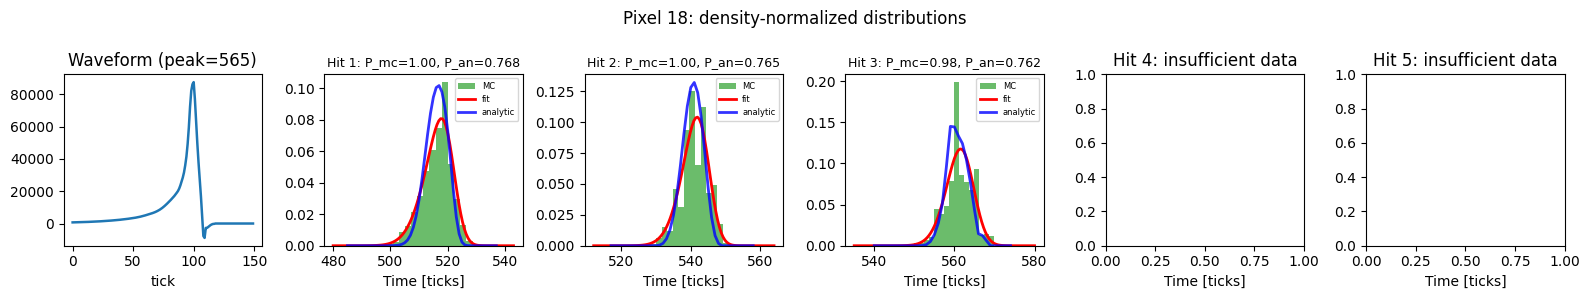

In [ ]:
# Show comparison for several pixels with varying signal strengths
for idx in range(100):
    if idx < len(sorted_idx):
        plot_with_analytic_density(sorted_idx[idx], waveforms, hit_adc, hit_time, n_variations,
                                   ticks_prob, hit_prob)

In [10]:
# Quantitative comparison: expected tick vs MC mean tick
mc_mean_ticks = []
analytic_expected_ticks = []
mc_hit_probs = []
analytic_hit_probs = []

for pix_idx in range(waveforms.shape[0]):
    for hit_idx in range(1, min(6, hit_time.shape[2])):  # Skip hit 0
        time_vals = hit_time[:, pix_idx, hit_idx]
        mask = time_vals < 1995
        time_vals = time_vals[mask]
        
        if len(time_vals) > 1 and len(time_vals)/n_variations > 0.01:
            mc_mean_ticks.append(np.mean(time_vals))
            analytic_expected_ticks.append(float(expected_ticks[pix_idx, hit_idx]))
            mc_hit_probs.append(len(time_vals) / n_variations)
            analytic_hit_probs.append(float(hit_prob[pix_idx, hit_idx]))

mc_mean_ticks = np.array(mc_mean_ticks)
analytic_expected_ticks = np.array(analytic_expected_ticks)
mc_hit_probs = np.array(mc_hit_probs)
analytic_hit_probs = np.array(analytic_hit_probs)

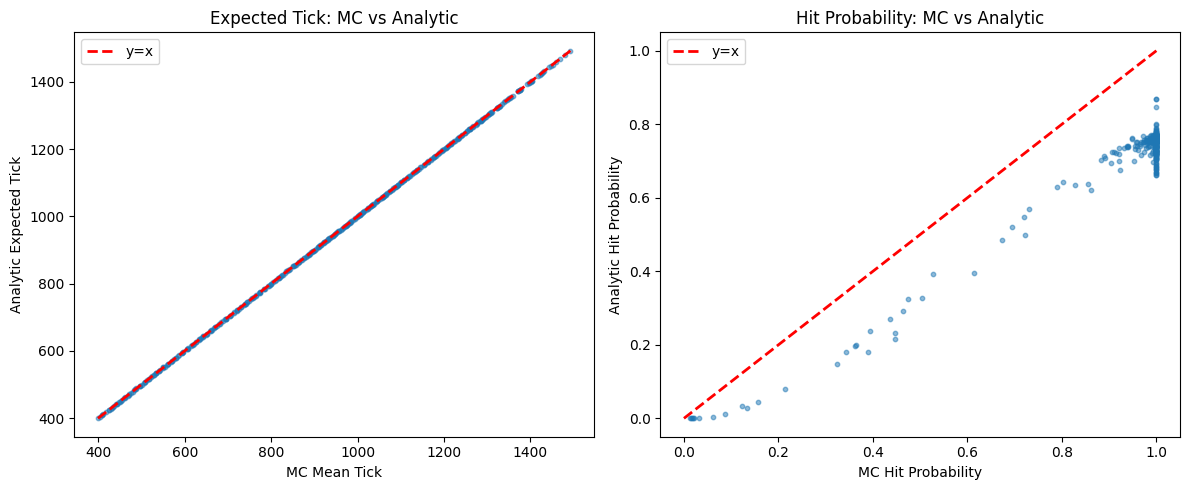

Tick correlation: 1.0000
Probability correlation: 0.9842


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Expected tick comparison
ax = axes[0]
ax.scatter(mc_mean_ticks, analytic_expected_ticks, alpha=0.5, s=10)
lims = [min(mc_mean_ticks.min(), analytic_expected_ticks.min()),
        max(mc_mean_ticks.max(), analytic_expected_ticks.max())]
ax.plot(lims, lims, 'r--', lw=2, label='y=x')
ax.set_xlabel('MC Mean Tick')
ax.set_ylabel('Analytic Expected Tick')
ax.set_title('Expected Tick: MC vs Analytic')
ax.legend()

# Hit probability comparison
ax = axes[1]
ax.scatter(mc_hit_probs, analytic_hit_probs, alpha=0.5, s=10)
ax.plot([0, 1], [0, 1], 'r--', lw=2, label='y=x')
ax.set_xlabel('MC Hit Probability')
ax.set_ylabel('Analytic Hit Probability')
ax.set_title('Hit Probability: MC vs Analytic')
ax.legend()

plt.tight_layout()
plt.show()

print(f"Tick correlation: {np.corrcoef(mc_mean_ticks, analytic_expected_ticks)[0,1]:.4f}")
print(f"Probability correlation: {np.corrcoef(mc_hit_probs, analytic_hit_probs)[0,1]:.4f}")

In [29]:
hit_prob[3,:]

Array([0.9999999 , 0.80082464, 0.79861677, 0.6439619 , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ],      dtype=float32)